In [ ]:
import pandas as pd
import re
import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

In [ ]:
df = pd.read_parquet("hf://datasets/dair-ai/emotion/unsplit/train-00000-of-00001.parquet")
df.head(20)

In [4]:
emotion_map = {
    0: "sadness",
    1: "joy",
    2: "love",
    3: "anger",
    4: "fear",
    5: "surprise"
}

df['emotion'] = df['label'].map(emotion_map)
df.head()

,text,label,emotion
0,i feel awful about it too because it s my job ...,0,sadness
1,im alone i feel awful,0,sadness
2,ive probably mentioned this before but i reall...,1,joy
3,i was feeling a little low few days back,0,sadness
4,i beleive that i am much more sensitive to oth...,2,love


In [5]:
df.isnull().sum()

text       0
label      0
emotion    0
dtype: int64

In [6]:
df.duplicated(subset=["text"]).sum()

np.int64(22987)

In [7]:
df.shape

(416809, 3)

In [8]:
df = df.drop_duplicates(subset="text")
df.shape

(393822, 3)

In [9]:
df.head()

,text,label,emotion
0,i feel awful about it too because it s my job ...,0,sadness
1,im alone i feel awful,0,sadness
2,ive probably mentioned this before but i reall...,1,joy
3,i was feeling a little low few days back,0,sadness
4,i beleive that i am much more sensitive to oth...,2,love


In [10]:
df['text'] = df['text'].str.lower()
df['text'] = df['text'].apply(
    lambda x: re.sub(r'[^a-zA-Z\s]', '', x)
)

In [11]:
df['text'] = df['text'].apply(
    lambda x: re.sub(r'\s+', ' ', x).strip()
)

In [12]:
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')

[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\meett\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\meett\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\meett\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


True

In [13]:
df['tokens'] = df['text'].apply(word_tokenize)

In [14]:
stop_words = set(stopwords.words('english'))
stop_words = stop_words - {
    'not',
    'no',
    'never',
    'nor'
}

In [15]:
lemm = WordNetLemmatizer()

def preprocess(text):
  words = word_tokenize(text)
  words = [
      lemm.lemmatize(word) for word in words if word not in stop_words
  ]
  return ' '.join(words)

df['clean_text'] = df['text'].apply(preprocess)

In [16]:
df.head(10)

,text,label,emotion,tokens,clean_text
0,i feel awful about it too because it s my job ...,0,sadness,"[i, feel, awful, about, it, too, because, it, ...",feel awful job get position succeed happen
1,im alone i feel awful,0,sadness,"[im, alone, i, feel, awful]",im alone feel awful
2,ive probably mentioned this before but i reall...,1,joy,"[ive, probably, mentioned, this, before, but, ...",ive probably mentioned really feel proud actua...
3,i was feeling a little low few days back,0,sadness,"[i, was, feeling, a, little, low, few, days, b...",feeling little low day back
4,i beleive that i am much more sensitive to oth...,2,love,"[i, beleive, that, i, am, much, more, sensitiv...",beleive much sensitive people feeling tend com...
5,i find myself frustrated with christians becau...,2,love,"[i, find, myself, frustrated, with, christians...",find frustrated christian feel constantly talk...
6,i am one of those people who feels like going ...,1,joy,"[i, am, one, of, those, people, who, feels, li...",one people feel like going gym worthwhile hour
7,i feel especially pleased about this as this h...,1,joy,"[i, feel, especially, pleased, about, this, as...",feel especially pleased long time coming
8,i was struggling with these awful feelings and...,1,joy,"[i, was, struggling, with, these, awful, feeli...",struggling awful feeling saying sweet thing no...
9,i feel so enraged but helpless at the same time,3,anger,"[i, feel, so, enraged, but, helpless, at, the,...",feel enraged helpless time


In [17]:
X = df['clean_text']
Y = df['label']

x_train, x_test, y_train, y_test = train_test_split(X, Y, test_size=0.2, random_state=42, stratify=Y)

In [18]:
tfidf = TfidfVectorizer(max_features=5000, ngram_range=(1, 2))

In [19]:
x_train = tfidf.fit_transform(x_train)
x_test = tfidf.transform(x_test)

In [20]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import classification_report, confusion_matrix

In [21]:
BATCH = 256

class SparseGen(tf.keras.utils.Sequence):
    def __init__(self, X, y, batch=BATCH, shuffle=True):
        self.X, self.y = X, np.asarray(y)
        self.batch, self.shuffle = batch, shuffle
        self.idx = np.arange(X.shape[0])
        self.on_epoch_end()

    def __len__(self):
        return int(np.ceil(len(self.idx) / self.batch))

    def __getitem__(self, i):
        b = self.idx[i*self.batch:(i+1)*self.batch]
        return self.X[b].toarray().astype("float32"), self.y[b]

    def on_epoch_end(self):
        if self.shuffle:
            np.random.shuffle(self.idx)

train_gen = SparseGen(x_train, y_train)
test_gen  = SparseGen(x_test, y_test, shuffle=False)

In [22]:
model = Sequential([
    Input(shape=(5000,)),
    Dense(512, activation="relu"),
    Dropout(0.4),
    Dense(256, activation="relu"),
    Dropout(0.3),
    Dense(128, activation="relu"),
    Dense(6, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
model.summary()

C:\Users\meett\anaconda3\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 512)            │     2,560,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,725,510 (10.40 MB)

 Trainable params: 2,725,510 (10.40 MB)

 Non-trainable params: 0 (0.00 B)

In [23]:
early_stop = EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True)

history = model.fit(
    train_gen,
    validation_data=test_gen,
    epochs=15,
    callbacks=[early_stop]
)

Epoch 1/15


C:\Users\meett\anaconda3\Lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


1231/1231 ━━━━━━━━━━━━━━━━━━━━ 127s 100ms/step - accuracy: 0.9080 - loss: 0.2424 - val_accuracy: 0.9450 - val_loss: 0.1257
Epoch 2/15
1231/1231 ━━━━━━━━━━━━━━━━━━━━ 129s 105ms/step - accuracy: 0.9552 - loss: 0.1055 - val_accuracy: 0.9452 - val_loss: 0.1253
Epoch 3/15
1231/1231 ━━━━━━━━━━━━━━━━━━━━ 121s 98ms/step - accuracy: 0.9660 - loss: 0.0787 - val_accuracy: 0.9465 - val_loss: 0.1308
Epoch 4/15
1231/1231 ━━━━━━━━━━━━━━━━━━━━ 126s 102ms/step - accuracy: 0.9747 - loss: 0.0586 - val_accuracy: 0.9457 - val_loss: 0.1512


In [24]:
y_pred = np.argmax(model.predict(test_gen), axis=1)

print(classification_report(y_test, y_pred,
      target_names=["sadness","joy","love","anger","fear","surprise"]))
print(confusion_matrix(y_test, y_pred))

308/308 ━━━━━━━━━━━━━━━━━━━━ 12s 38ms/step
              precision    recall  f1-score   support

     sadness       0.97      0.96      0.97     23701
         joy       0.96      0.96      0.96     27021
        love       0.87      0.91      0.89      5879
       anger       0.96      0.92      0.94     10941
        fear       0.91      0.93      0.92      8731
    surprise       0.86      0.86      0.86      2492

    accuracy                           0.95     78765
   macro avg       0.92      0.92      0.92     78765
weighted avg       0.95      0.95      0.95     78765

[[22841   309    54   241   222    34]
 [  189 25865   723    61    69   114]
 [   37   433  5374    11    14    10]
 [  334   227    36 10106   233     5]
 [  162   150    10    89  8123   197]
 [   18    91     9    15   218  2141]]


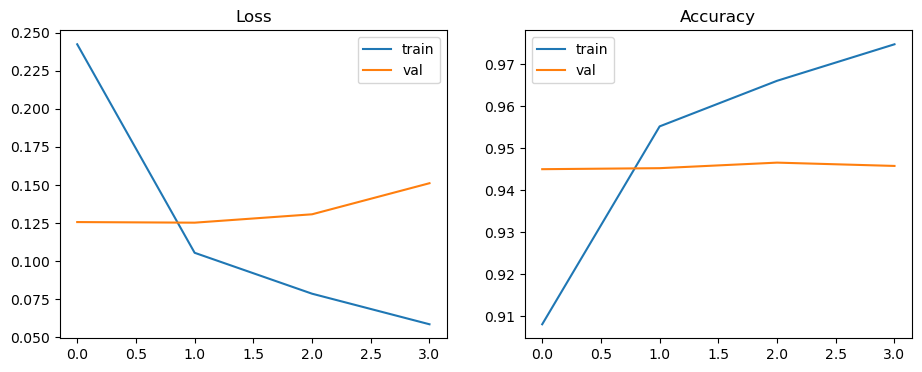

In [25]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(history.history["loss"], label="train"); ax[0].plot(history.history["val_loss"], label="val"); ax[0].set_title("Loss"); ax[0].legend()
ax[1].plot(history.history["accuracy"], label="train"); ax[1].plot(history.history["val_accuracy"], label="val"); ax[1].set_title("Accuracy"); ax[1].legend()
plt.show()

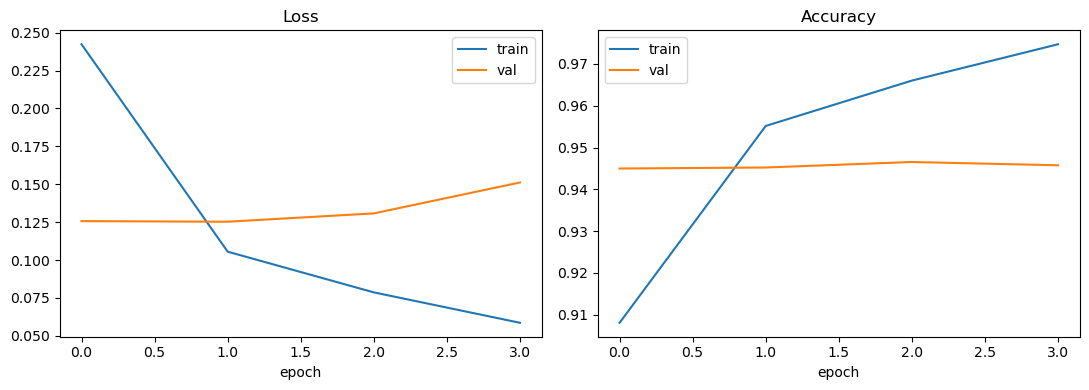

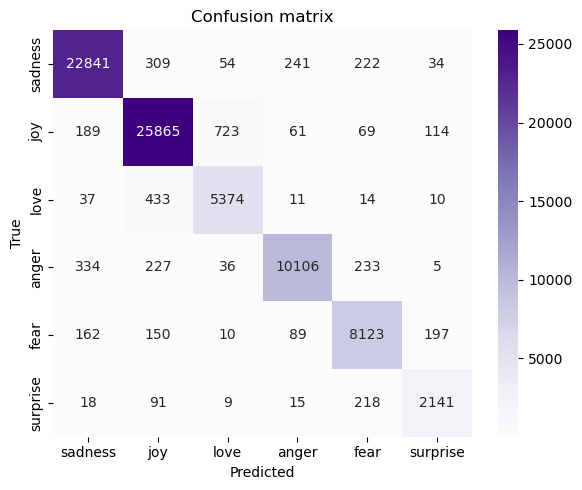

C:\Users\meett\OneDrive\Desktop\SCET\SCET_SEM_5\AI\OEP
['confusion_matrix.png', 'curves.png']


In [28]:
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# --- 1. Loss and accuracy curves ---
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(history.history["loss"], label="train")
ax[0].plot(history.history["val_loss"], label="val")
ax[0].set_title("Loss"); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].plot(history.history["accuracy"], label="train")
ax[1].plot(history.history["val_accuracy"], label="val")
ax[1].set_title("Accuracy"); ax[1].set_xlabel("epoch"); ax[1].legend()
plt.tight_layout()
plt.savefig("curves.png", dpi=200)
plt.show()

# --- 2. Confusion matrix ---
labels = ["sadness", "joy", "love", "anger", "fear", "surprise"]
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Purples",
            xticklabels=labels, yticklabels=labels)
plt.xlabel("Predicted"); plt.ylabel("True"); plt.title("Confusion matrix")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=200)
plt.show()

# --- 3. Check they exist ---
print(os.getcwd())
print([f for f in os.listdir() if f.endswith(".png")])